# Price and reporting patterns

Compare distributions, regional variation, seasonality and reporting gaps.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

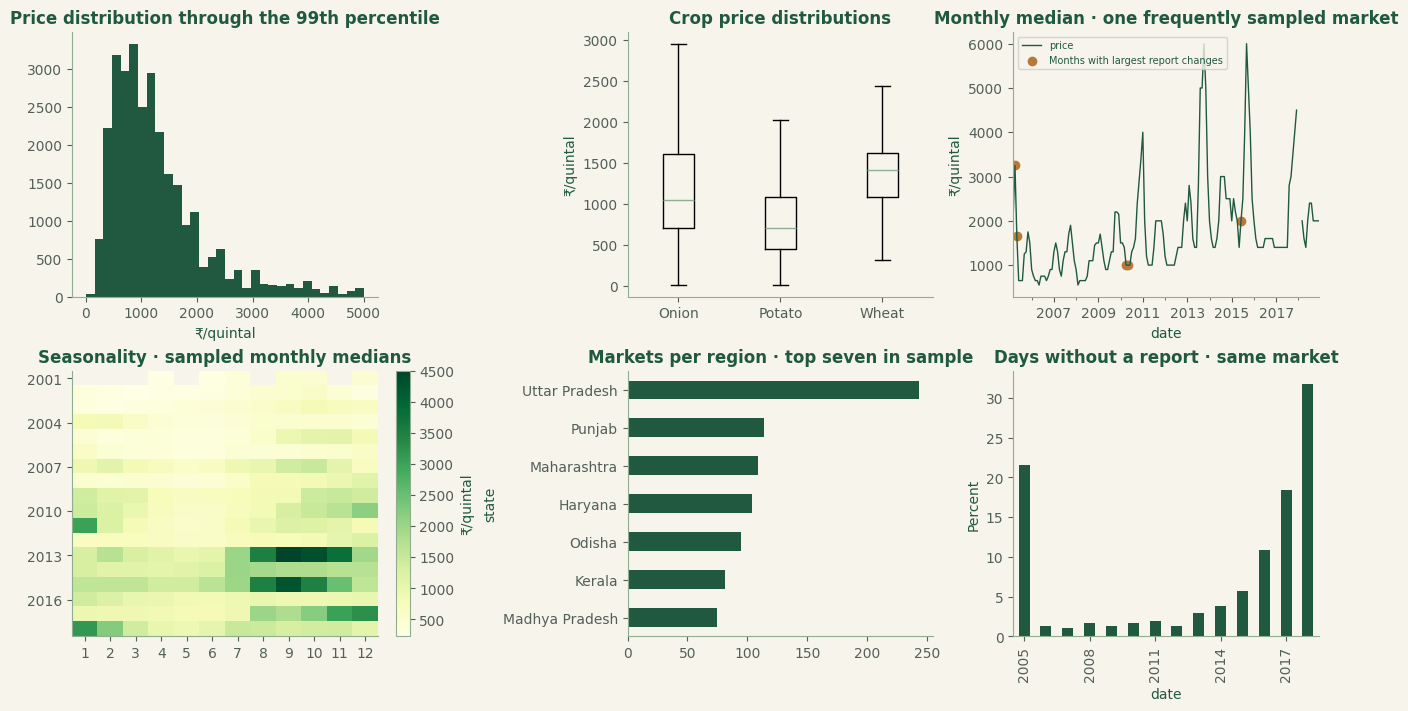

,markets,median
state,,
Uttar Pradesh,243,1015.0
Punjab,114,1000.0
Maharashtra,109,756.5
Haryana,104,1000.0
Odisha,95,1500.0
Kerala,81,2200.0
Madhya Pradesh,75,600.0


interactive(children=(Dropdown(description='Crop', options=('Onion', 'Potato', 'Wheat'), value='Onion'), Butto…

In [2]:
def explore(crop):
    frame = archive_sample(crop).assign(month=lambda x: x.date.dt.month, year=lambda x: x.date.dt.year)
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
    ax = axes.ravel()
    upper = frame.price.quantile(.99)
    ax[0].hist(frame.loc[frame.price <= upper, "price"], bins=32)
    ax[0].set(title="Price distribution through the 99th percentile", xlabel="₹/quintal")
    ax[1].boxplot([archive_sample(c).price for c in CROPS], tick_labels=CROPS, showfliers=False)
    ax[1].set(title="Crop price distributions", ylabel="₹/quintal")
    series = development_market(crop).set_index("date").price
    series.resample("MS").median().plot(ax=ax[2], lw=1)
    unusual = series.pct_change().abs().nlargest(5)
    monthly = series.resample("MS").median()
    months = unusual.index.to_period("M").to_timestamp().unique()
    ax[2].scatter(months, monthly.reindex(months), c=GOLD, label="Months with largest report changes")
    ax[2].set(title="Monthly median · one frequently sampled market", ylabel="₹/quintal")
    ax[2].legend(fontsize=7)
    heat = frame.pivot_table(index="year", columns="month", values="price", aggfunc="median")
    fig.colorbar(ax[3].imshow(heat, aspect="auto", cmap="YlGn"), ax=ax[3], label="₹/quintal")
    ax[3].set(title="Seasonality · sampled monthly medians", xticks=range(12), xticklabels=range(1,13),
              yticks=range(0,len(heat),3), yticklabels=heat.index[::3])
    regional = frame.groupby("state", observed=True).agg(markets=("market", "nunique"), median=("price", "median")).nlargest(7,"markets")
    regional.markets.sort_values().plot.barh(ax=ax[4], title="Markets per region · top seven in sample")
    daily = series.resample("D").size()
    (100*(daily == 0).resample("YS").mean()).plot.bar(ax=ax[5], title="Days without a report · same market")
    ax[5].set(ylabel="Percent", xticks=range(0,len(daily.resample("YS").size()),3),
              xticklabels=daily.resample("YS").size().index.year[::3])
    plt.show()
    display(regional.round(1))

controls(explore, crop=CROPS)

Charts use audited prices through 2018. Sample market counts describe coverage in the sampled rows. The single-market gap chart uses calendar days from its first to last observation, including partial boundary years.

**Takeaway** · Seasonal price patterns and reporting density vary across crops and markets. Inspect both before comparing estimates.

**Next** · Review the cleaning decisions in Notebook 04.